In this notebook we will compare the predictions from MW11 model with their Fig. B1. For that reason, both the cosmology and the cddf stated in the paper will me used

In [1]:
import h5py
from lace.cosmo import cosmology
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator

import sys
import os
sys.path.append(os.path.abspath(".."))
from w1_w2 import wave_to_fft_profile, compute_w1_w2

In [2]:
wave_log = np.linspace(np.log10(2800), np.log10(6800), 2**12) # Angstrom
wave = 10**wave_log
bias_hcd, bias_lya = 2, -0.18

In [3]:
# MW11 cosmology
hubble, z = 0.71, 2.5
ombh2, omegam = 0.046*(hubble**2), 0.27
omch2 = omegam*(hubble**2)-ombh2
ns, As = 0.96, 2e-9
Fhcd = 0.9779  # Mean flux

cosmo = cosmology.Cosmology()
cosmo.CAMBparams.set_cosmology(H0=100*hubble, ombh2=ombh2, omch2=omch2)
cosmo.CAMBparams.InitPower.set_params(As=As, ns=ns)
print('WARNING: Changed to ASTRID cosmology (It does not affect the f(NHI, X) function)')

# P3D

We will compare with the thin lines because we know their logNhi ranges

In [4]:
def f_Nhi(colden, k, b):
    y = k*(colden**b)
    return y

k1, b1 = 280.14, -1.2
k2, b2 = 4.24e14, -1.8

NHirange = np.linspace(19, 20) 
colden1, colden2 = NHirange[NHirange < 20.3], NHirange[NHirange >= 20.3]
fNHiX = np.concatenate([f_Nhi(10**colden1, k1, b1), f_Nhi(10**colden2, k2, b2)])

## W1 and W2

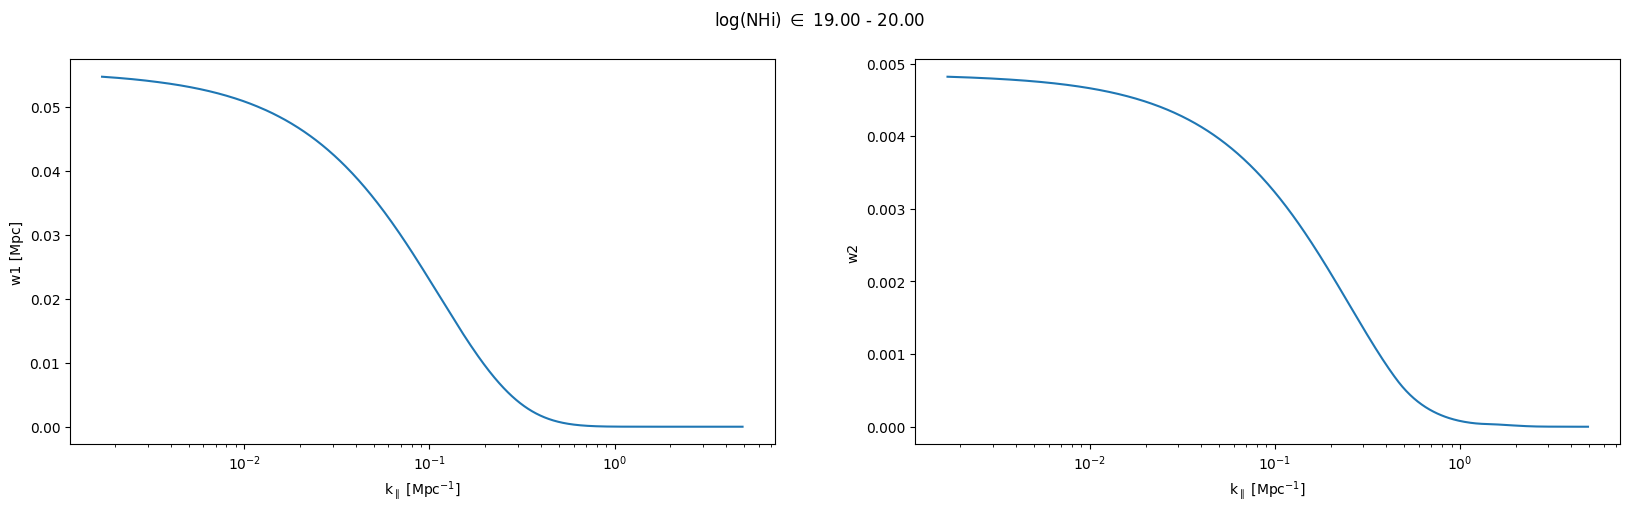

In [5]:
k_w1w2, w1, w2 = compute_w1_w2(wave, NHirange, fNHiX, z, hubble, omegam, resample=True)

plt.figure(figsize=(20, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()))

plt.subplot(1, 2, 1)
plt.plot(k_w1w2, w1)
plt.ylabel(r'w1 [Mpc]')
plt.xscale('log')
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]');

plt.subplot(1, 2, 2)
plt.plot(k_w1w2, w2)
plt.ylabel(r'w2')

plt.xscale('log')
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]');

In [6]:
bias_hcd_flux = -2*w2[1]/0.9891  # Warning, this depends a lot on the cosmology
bias_hcd_flux

np.float64(-0.009742776718423881)

We will work in a grid of (k, mu), so for each value we will have a different k_los array. Let's create then the k_los grid and interpolate the w1 and w2 functions to it

In [7]:
mu = np.linspace(0, 1, 11)
k = np.logspace(-2.5, 0.5, len(k_w1w2))
k_los = k*mu[:, None]
k_perp = np.sqrt(k**2 - k_los**2)

w1_grid = np.interp(k_los, k_w1w2, w1)
w2_grid = np.interp(k_los, k_w1w2, w2)

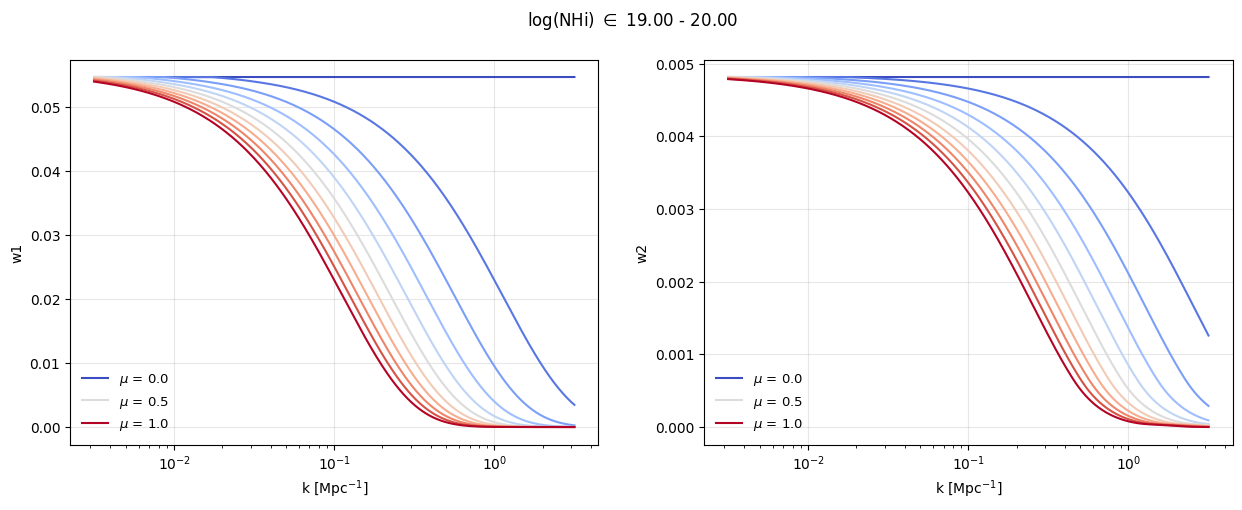

In [8]:
plt.figure(figsize=(15, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()))

plt.subplot(1, 2, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, w1_grid[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, w1_grid[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'w1');

plt.subplot(1, 2, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, w2_grid[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, w2_grid[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'w2');

## Plin

In [8]:
plin = cosmo.get_linP_Mpc(z, k)

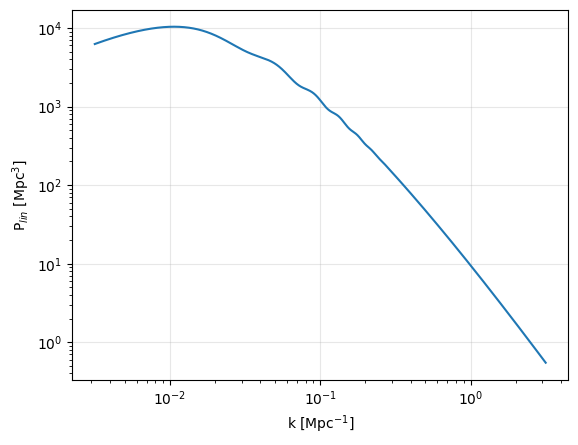

In [10]:
plt.plot(k, plin)
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{lin}$ [Mpc$^{3}$]');

## HCD field

In [9]:
p3d_hcd = (w2_grid**2)*((bias_hcd+mu[:, None]**2)**2)*plin

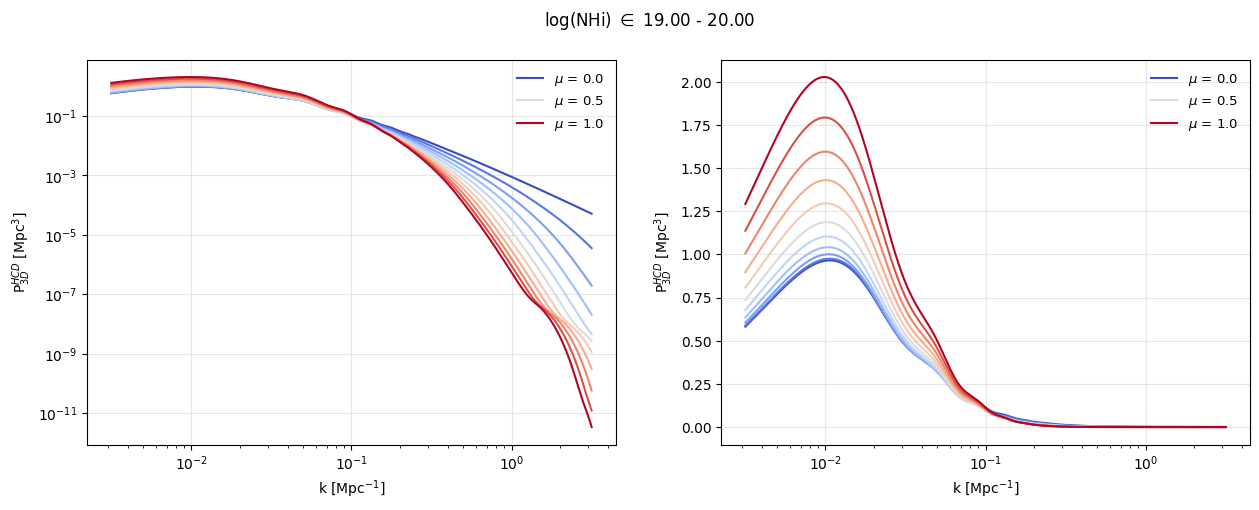

In [12]:
plt.figure(figsize=(15, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()));

plt.subplot(1, 2, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_hcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_hcd[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{HCD}$ [Mpc$^{3}$]');

plt.subplot(1, 2, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_hcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_hcd[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{HCD}$ [Mpc$^{3}$]');

## Lya field

In [10]:
dkms_dMpc = cosmo.get_dkms_dMpc(z)
k_d = 0.08*dkms_dMpc  # Mpc^-1
exp = np.exp(-(k_los**2/k_d**2))
p3d_lya = (bias_lya**2)*((1+mu[:, None]**2)**2)*exp*plin

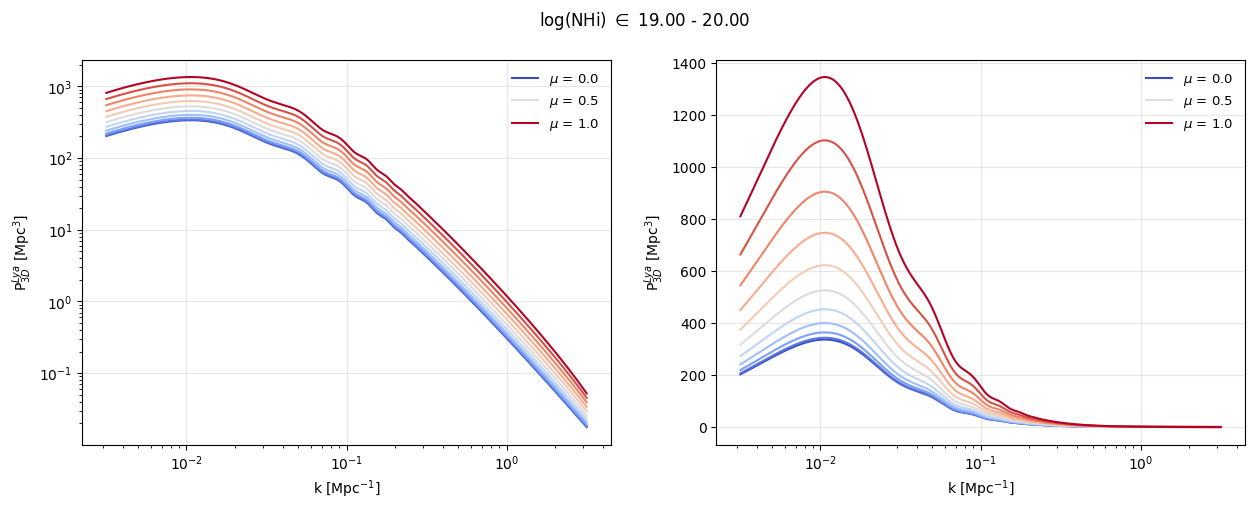

In [14]:
plt.figure(figsize=(15, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()));

plt.subplot(1, 2, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lya[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lya[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$ [Mpc$^{3}$]');

plt.subplot(1, 2, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lya[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lya[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$ [Mpc$^{3}$]');

## HCD x Lya field

In [11]:
dkms_dMpc = cosmo.get_dkms_dMpc(z)
k_d = 0.08*dkms_dMpc  # Mpc^-1
exp = np.exp(-(k_los**2/k_d**2))
p3d_lyahcd = w2_grid*(np.abs(bias_hcd) + mu[:, None]**2)*np.abs(bias_lya)*(1 + mu[:, None]**2)*plin*np.sqrt(exp)

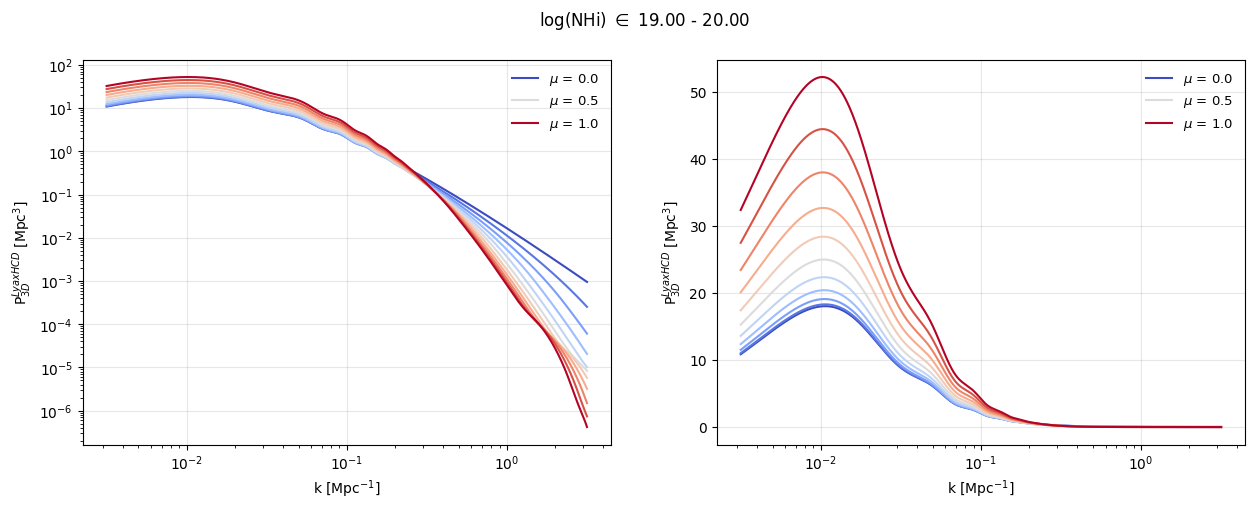

In [16]:
plt.figure(figsize=(15, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()));

plt.subplot(1, 2, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lyahcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lyahcd[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{LyaxHCD}$ [Mpc$^{3}$]');

plt.subplot(1, 2, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lyahcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lyahcd[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{LyaxHCD}$ [Mpc$^{3}$]');

## Comparison with MW11 figure

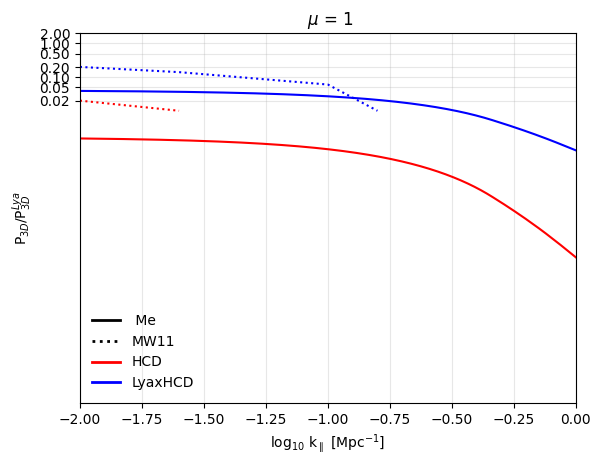

In [17]:
from matplotlib.lines import Line2D

k_mw11 = [-2, -1.6, -1, -0.8]
ratio_hcd_mw11 = [0.02, 0.01, np.nan, np.nan]
ratio_lyahcd_mw11 = [0.2, 0.14, 0.06, 0.01]

i = 10  # So that k = k_los
plt.plot(np.log10(k), p3d_hcd[i]/p3d_lya[i], color='red')
plt.plot(k_mw11, ratio_hcd_mw11, color='red', linestyle=':')
plt.plot(np.log10(k), p3d_lyahcd[i]/p3d_lya[i], color='blue')
plt.plot(k_mw11, ratio_lyahcd_mw11, color='blue', linestyle=':')
plt.yscale('log')
yticks = np.array([0.02, 0.05, 0.10, 0.20, 0.50, 1.00, 2.00])
plt.yticks(yticks, [f"{y:.2f}" for y in yticks])
plt.grid(alpha=0.3)
handles = [Line2D([0], [0], color='black', lw=2, linestyle='-', label=' Me'),
    Line2D([0], [0], color='black', lw=2, linestyle=':', label='MW11'),
    Line2D([0], [0], color='red', lw=2, label='HCD'),
    Line2D([0], [0], color='blue', lw=2, label=r'LyaxHCD')]
plt.legend(handles=handles, frameon=False)
plt.xlabel(r'log$_{10}$ k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$/P$_{3D}^{Lya}$')
plt.xlim(-2, 0)
plt.title(r' $\mu$ = 1');

# P1D

In [12]:
interp_hcd = RegularGridInterpolator((mu, k), p3d_hcd, bounds_error=False, fill_value=0.0)
interp_lya = RegularGridInterpolator((mu, k), p3d_lya, bounds_error=False, fill_value=0.0)
interp_lyahcd = RegularGridInterpolator((mu, k), p3d_lyahcd, bounds_error=False, fill_value=0.0)

In [13]:
kperp = np.logspace(np.log10(k_perp[:-1, 0].min()), np.log10(k_perp[:-1, -1].max()), len(k_perp[0]))
KPAR, KPERP = np.meshgrid(k_w1w2, kperp, indexing='ij')
K = np.sqrt(KPAR**2 + KPERP**2)
MU = KPAR/K
points_target = np.stack([MU.ravel(), K.ravel()], axis=-1)

In [14]:
# HCD
p3d_hcd_newgrid = interp_hcd(points_target).reshape(K.shape)
p1d_hcd = w1 + np.trapezoid(kperp*p3d_hcd_newgrid, kperp)/(2*np.pi)

# LYA
p3d_lya_newgrid = interp_lya(points_target).reshape(K.shape)
p1d_lya = np.trapezoid(kperp*p3d_lya_newgrid, kperp)/(2*np.pi)

# LYAxHCD
p3d_lyahcd_newgrid = interp_lyahcd(points_target).reshape(K.shape)
p1d_lyahcd = np.trapezoid(kperp*p3d_lyahcd_newgrid, kperp)/(2*np.pi)

## Comparison with MW11 figure

/tmp/ipykernel_171609/602951422.py:8: RuntimeWarning: invalid value encountered in divide
  plt.plot(np.log10(k_w1w2), (p1d_hcd-w1)/p1d_lya, color='red')
/tmp/ipykernel_171609/602951422.py:9: RuntimeWarning: divide by zero encountered in divide
  plt.plot(np.log10(k_w1w2), w1/p1d_lya, color='blue')
/tmp/ipykernel_171609/602951422.py:9: RuntimeWarning: invalid value encountered in divide
  plt.plot(np.log10(k_w1w2), w1/p1d_lya, color='blue')
/tmp/ipykernel_171609/602951422.py:12: RuntimeWarning: invalid value encountered in divide
  plt.plot(np.log10(k_w1w2), p1d_lyahcd/p1d_lya, color='k')


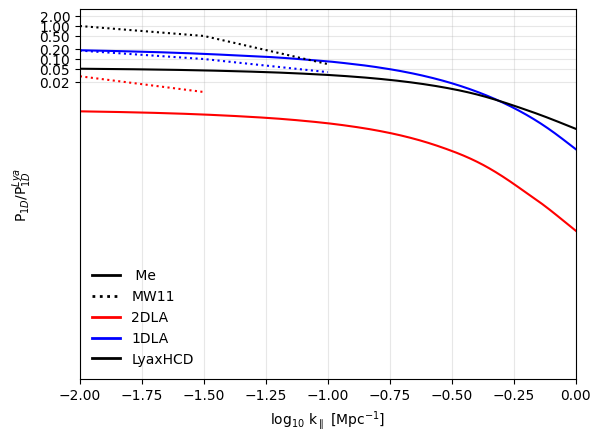

In [15]:
from matplotlib.lines import Line2D

k_mw11 = [-2, -1.5, -1]
ratio_2dla_mw11 = [0.03, 0.01, np.nan]
ratio_1dla_mw11 = [0.18, 0.1, 0.04]
ratio_lyahcd_mw11 = [1, 0.5, 0.07]

plt.plot(np.log10(k_w1w2), (p1d_hcd-w1)/p1d_lya, color='red')
plt.plot(np.log10(k_w1w2), w1/p1d_lya, color='blue')
plt.plot(k_mw11, ratio_2dla_mw11, color='red', linestyle=':')
plt.plot(k_mw11, ratio_1dla_mw11, color='blue', linestyle=':')
plt.plot(np.log10(k_w1w2), p1d_lyahcd/p1d_lya, color='k')
plt.plot(k_mw11, ratio_lyahcd_mw11, color='k', linestyle=':')
plt.yscale('log')
yticks = np.array([0.02, 0.05, 0.10, 0.20, 0.50, 1.00, 2.00])
plt.yticks(yticks, [f"{y:.2f}" for y in yticks])
plt.grid(alpha=0.3)
handles = [Line2D([0], [0], color='black', lw=2, linestyle='-', label=' Me'),
    Line2D([0], [0], color='black', lw=2, linestyle=':', label='MW11'),
    Line2D([0], [0], color='red', lw=2, label='2DLA'),
    Line2D([0], [0], color='blue', lw=2, label=r'1DLA'),
    Line2D([0], [0], color='k', lw=2, label=r'LyaxHCD')]
plt.legend(handles=handles, frameon=False)
plt.xlabel(r'log$_{10}$ k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'P$_{1D}$/P$_{1D}^{Lya}$')
plt.xlim(-2, 0);